# 2. The insect

Notebook 1 read the leaf. This one reads the **bug**, and answers the question
the project actually needs: *is this Helopeltis or not?*

It is a **separate model, not a next step in a pipeline.** The damage detector
draws boxes on lesions; a lesion crop contains no insect, so its output cannot
be fed here. One tool looks at a leaf, the other at an animal.

Three classes, because only one boundary is hard:

| class | why |
|---|---|
| `helopeltis` | the target — 577 photos, mostly *H. theivora*, the tea mosquito bug |
| `other_miridae` | **the hard negative** — same family, thousands of species |
| `other_insects` | the easy negative — bees, spiders, ants, butterflies |

Telling Helopeltis from a bee is free. Telling it from another mirid is the
entire problem.

In [1]:
import json, os, sys, warnings
from pathlib import Path

# Keep library warnings out of the saved output.
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams["figure.dpi"] = 110
print("project root:", ROOT.name)

project root: TeaGuard


In [2]:
import torch
from src.train import build_model, eval_tf, TASK_CLASSES

classes = TASK_CLASSES["helopeltis"]
model = build_model(num_classes=len(classes), freeze_backbone=False)
model.load_state_dict(torch.load(ROOT / "models" / "helopeltis_id.pt", map_location="cpu"))
model.eval()

def predict(path):
    with torch.no_grad():
        probs = torch.softmax(model(eval_tf(Image.open(path).convert("RGB")).unsqueeze(0)), 1)[0]
    i = int(probs.argmax())
    return classes[i], float(probs[i])

print("classes:", classes)

classes: ['helopeltis', 'other_miridae', 'other_insects']


## What Helopeltis looks like

Slender body, very long legs and antennae, dark with an orange pronotum, and a
small upright spine on the back. Almost always photographed on a green leaf.

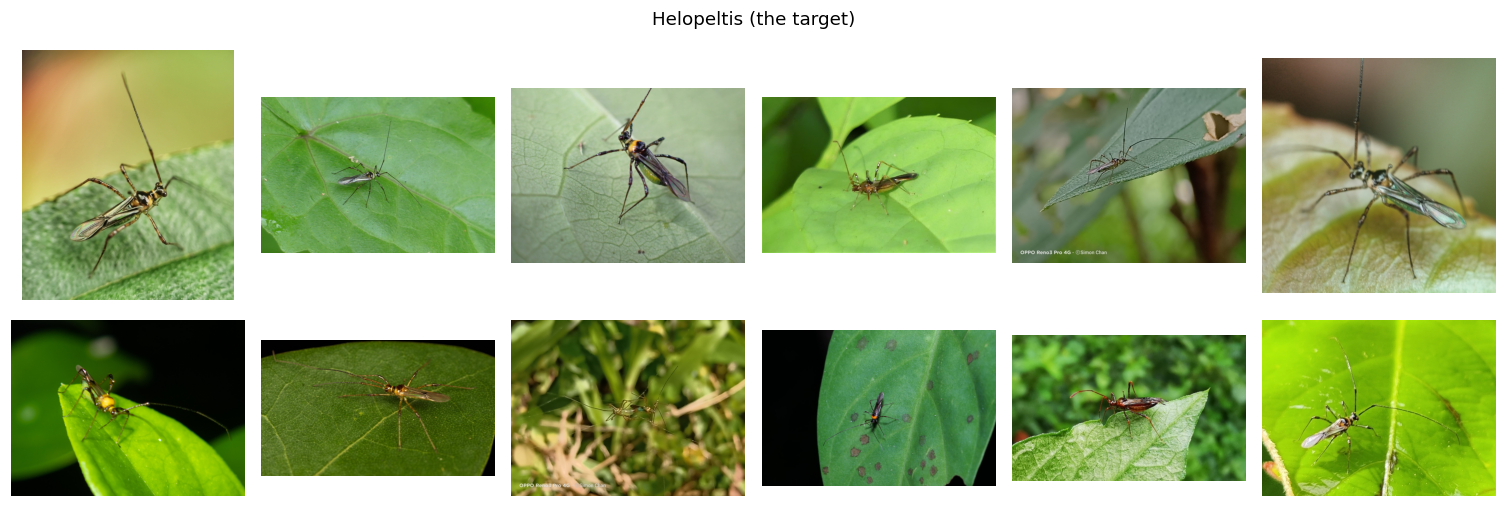

In [3]:
FAM = ROOT / "data" / "raw" / "insect_families"

def sheet(paths, title, cols=6, labeller=None):
    rows = (len(paths) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(2.3 * cols, 2.5 * rows))
    for ax, p in zip(np.array(axes).ravel(), paths):
        ax.imshow(Image.open(p).convert("RGB"))
        if labeller:
            txt, colour = labeller(p)
            ax.set_title(txt, fontsize=8, color=colour)
        ax.axis("off")
    for ax in np.array(axes).ravel()[len(paths):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=12)
    plt.tight_layout(); plt.show()

sheet(sorted((FAM / "helopeltis").glob("*.jpg"))[:12], "Helopeltis (the target)")

And here is the problem — other mirids. Same family, same silhouette, same
green leaf. This is what the model has to reject.

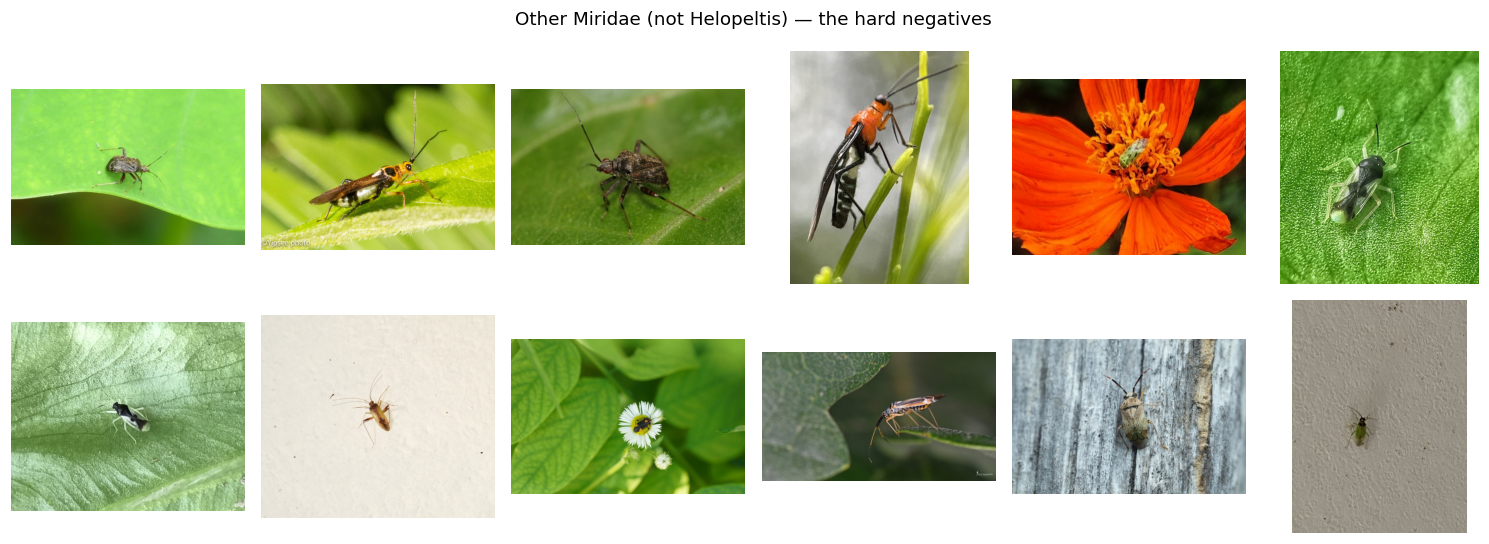

In [4]:
sheet(sorted((FAM / "other_miridae").glob("*.jpg"))[:12],
      "Other Miridae (not Helopeltis) — the hard negatives")

## How well it does

Measured on a held-out test split.

In [5]:
m = json.loads((ROOT / "models" / "helopeltis_id_metrics.json").read_text())
h = m["helopeltis"]
print(f"overall accuracy (3 classes) : {m['group_accuracy']:.3f}")
print(f"HELOPELTIS precision         : {h['precision']:.3f}")
print(f"HELOPELTIS recall            : {h['recall']:.3f}")
print(f"  missed as another mirid    : {h['missed_as_other_miridae']}")
print(f"  other mirids called Helo   : {h['other_miridae_called_helopeltis']}")
print()
for cls in m["classes"]:
    r = m["per_class"][cls]
    print(f"  {cls:15s} precision {r['precision']:.2f}  recall {r['recall']:.2f}  n={int(r['support'])}")

overall accuracy (3 classes) : 0.819
HELOPELTIS precision         : 0.862
HELOPELTIS recall            : 0.872
  missed as another mirid    : 7
  other mirids called Helo   : 8

  helopeltis      precision 0.86  recall 0.87  n=86
  other_miridae   precision 0.71  recall 0.82  n=131
  other_insects   precision 0.89  recall 0.80  n=203


## The trap: was it reading the insect, or the continent?

Here is where the number nearly became another mirage.

Helopeltis photos on iNaturalist come from **tropical Asia** — Singapore, Hong
Kong, India, Taiwan. The other-mirid photos came overwhelmingly from the **USA
and Europe**. A model can score beautifully on that split by learning what
tropical vegetation looks like, and never once look at the bug.

So we built the control the training set lacked: **other mirids photographed in
Helopeltis's own regions**. If the model were reading geography, it would call
most of them Helopeltis.

In [6]:
geo = json.loads((ROOT / "models" / "helopeltis_geo_control.json").read_text())
print(f"control images      : {geo['n_control_images']}  (mirids from Asia, NOT Helopeltis)")
print(f"predicted breakdown : {geo['predicted']}")
print()
print(f"false positives, same region : {geo['false_positive_rate_same_region']:.3f}")
print(f"false positives, test split  : {geo['false_positive_rate_test_split']:.3f}")
print(f"ratio                        : "
      f"{geo['false_positive_rate_same_region'] / geo['false_positive_rate_test_split']:.1f}x")

control images      : 208  (mirids from Asia, NOT Helopeltis)
predicted breakdown : {'helopeltis': 23, 'other_miridae': 163, 'other_insects': 22}

false positives, same region : 0.111
false positives, test split  : 0.061
ratio                        : 1.8x


The first time we ran this, the same-region false-positive rate was **22.8%**
against 9.4% on the ordinary test split — a 2.4x gap. Geography was doing a
large part of the work.

The fix was to add 301 mirids **from those same regions** to the training
negatives, so the model had to learn the animal. The rate above is what came
out afterwards. Recall did not drop, which was the risk: the model got better at
discriminating, it did not just become timid.

## Its actual mistakes

These are the control images it still calls Helopeltis. Note the confidences.

23 of 208 same-region mirids called Helopeltis



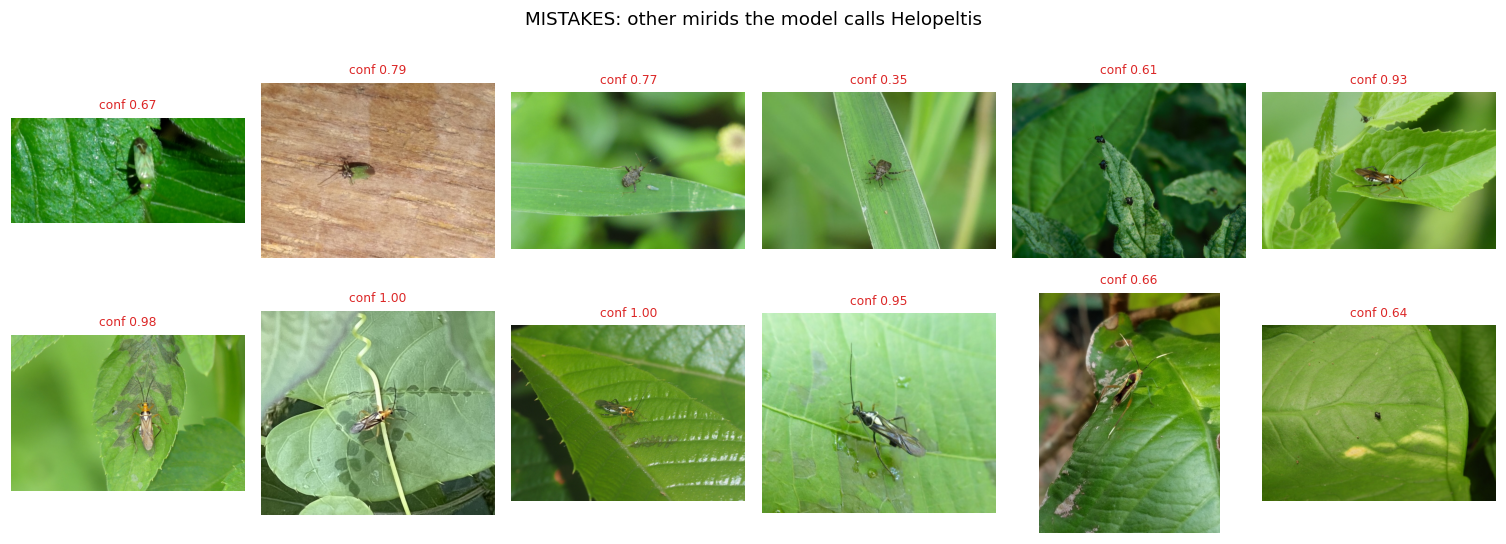

In [7]:
control = sorted((FAM / "_geo_control").glob("*.jpg"))
errors = [(p, predict(p)) for p in control]
false_positives = [(p, c) for p, (cls, c) in errors if cls == "helopeltis"]
print(f"{len(false_positives)} of {len(control)} same-region mirids called Helopeltis\n")

sheet([p for p, _ in false_positives[:12]],
      "MISTAKES: other mirids the model calls Helopeltis",
      labeller=lambda p: (f"conf {dict(false_positives)[p]:.2f}", "#dc2626"))

Two things to take from that grid.

**The mistakes are reasonable.** They are slender, long-legged mirids on green
leaves — the same silhouette as the target. It is not confusing Helopeltis with
a butterfly.

**But it is confidently wrong.** Several of those errors carry confidences above
0.95. That means **you cannot use the confidence score as a safety filter**: a
0.99 does not mean it is right. Any app built on this must not show "99% sure".

## The honest headline

> Recall 0.87, precision 0.86 — but on mirids from its own regions, which is the
> realistic case, it misidentifies roughly **1 in 9**.

Both numbers belong together. The first one alone is only true because the
easy negatives came from another continent.

Next: [3. The moment](03_the_moment.ipynb).